# 📘 Notebook: Chapter 2 - How LLMs Interpret Prompts

This notebook accompanies Chapter 2 **“How LLMs Interpret Prompts”** and provides
hands-on demonstrations of the core mechanisms that shape language model behaviour.
Through a series of small, focused experiments, you will explore how LLMs process text,
how they represent prompts internally, and why seemingly minor variations in structure
or ordering can lead to noticeably different outputs.

### What this notebook covers

1. **Tokenising Text with `tiktoken`**  
   Understand how raw text is broken into tokens and why small spelling or punctuation changes
   alter tokenisation.

2. **Inspecting Context and Tokens**  
   Examine how tokens fill a model’s context window and where important instructions appear
   in that sequence.

3. **Visualising a Context Window**  
   Use a simple schematic plot to illustrate recency effects and the role of the context limit.

4. **Seed-controlled Sampling and Reproducibility**  
   Observe how fixing a random seed stabilises generation, and how changing the seed produces
   alternative—but valid—continuations.

5. **Prompt Reordering and Order Effects**  
   Compare outputs from logically equivalent prompts whose instruction order is rearranged,
   revealing how recency and prompt geometry influence model behaviour.

---

Together, these exercises build an intuitive understanding of how LLMs interpret prompts,
why they can be sensitive to small changes, and how prompt design choices affect reliability
and output quality.

## 1. Tokenising Text with `tiktoken`

This section shows how an OpenAI-style tokenizer (using `tiktoken`) breaks a prompt
into tokens. We compare small variations such as spelling and punctuation and inspect
the resulting token IDs and text pieces.


In [2]:
# !pip install tiktoken transformers accelerate sentencepiece -q

import tiktoken

In [3]:
enc = tiktoken.get_encoding("cl100k_base")

def pretty_print_tokens(text: str):
    print(f"Text: {text!r}")
    tokens = enc.encode(text)
    print("Token IDs:", tokens)
    print("Token count:", len(tokens))
    print("\nID\tToken")
    print("-" * 20)
    for token in tokens:
        decoded = enc.decode([token])
        print(f"{token}\t{decoded!r}")
    print("\n" + "=" * 40 + "\n")

# Baseline example
pretty_print_tokens("Summarise the following report in three bullet points.")

# Variation 1: US spelling
pretty_print_tokens("Summarize the following report in three bullet points.")

# Variation 2: remove final punctuation
pretty_print_tokens("Summarise the following report in three bullet points")

# Variation 3: small change in wording
pretty_print_tokens("Summarise the report below in three bullet points.")

Text: 'Summarise the following report in three bullet points.'
Token IDs: [9370, 5730, 1082, 279, 2768, 1934, 304, 2380, 17889, 3585, 13]
Token count: 11

ID	Token
--------------------
9370	'Sum'
5730	'mar'
1082	'ise'
279	' the'
2768	' following'
1934	' report'
304	' in'
2380	' three'
17889	' bullet'
3585	' points'
13	'.'


Text: 'Summarize the following report in three bullet points.'
Token IDs: [9370, 5730, 553, 279, 2768, 1934, 304, 2380, 17889, 3585, 13]
Token count: 11

ID	Token
--------------------
9370	'Sum'
5730	'mar'
553	'ize'
279	' the'
2768	' following'
1934	' report'
304	' in'
2380	' three'
17889	' bullet'
3585	' points'
13	'.'


Text: 'Summarise the following report in three bullet points'
Token IDs: [9370, 5730, 1082, 279, 2768, 1934, 304, 2380, 17889, 3585]
Token count: 10

ID	Token
--------------------
9370	'Sum'
5730	'mar'
1082	'ise'
279	' the'
2768	' following'
1934	' report'
304	' in'
2380	' three'
17889	' bullet'
3585	' points'


Text: 'Summarise the report below in

## 2. Inspecting Context and Tokens

This example shows how an LLM breaks a prompt into tokens and how many positions in the
context window those tokens occupy. We also highlight where “important” instructions
appear within the sequence. This helps illustrate how prompt structure interacts with
context length and why placement of constraints matters.

We use the OpenAI-style tokenizer `tiktoken` for this demonstration.


In [4]:
# OpenAI-style tokenizer (used by GPT-4, GPT-3.5, etc.)
enc = tiktoken.get_encoding("cl100k_base")

prompt = """
You are an AI assistant that helps with data analysis and reporting.
Follow these rules:
1. Be concise.
2. Use clear bullet points.
3. If you are uncertain, say so.

Now, summarise the following text in three bullet points:
<insert text here>
"""

# Encode the text into tokens
tokens = enc.encode(prompt)

print("Number of tokens:", len(tokens))
print("First 20 token IDs:", tokens[:20])
print("\n")

# Display mapping from token ID to decoded text
print("Token → Text mapping:\n")
for i, token_id in enumerate(tokens):
    decoded = enc.decode([token_id])
    print(f"{i:>4} | {token_id:>6} | {decoded!r}")


Number of tokens: 57
First 20 token IDs: [198, 2675, 527, 459, 15592, 18328, 430, 8779, 449, 828, 6492, 323, 13122, 627, 12763, 1521, 5718, 512, 16, 13]


Token → Text mapping:

   0 |    198 | '\n'
   1 |   2675 | 'You'
   2 |    527 | ' are'
   3 |    459 | ' an'
   4 |  15592 | ' AI'
   5 |  18328 | ' assistant'
   6 |    430 | ' that'
   7 |   8779 | ' helps'
   8 |    449 | ' with'
   9 |    828 | ' data'
  10 |   6492 | ' analysis'
  11 |    323 | ' and'
  12 |  13122 | ' reporting'
  13 |    627 | '.\n'
  14 |  12763 | 'Follow'
  15 |   1521 | ' these'
  16 |   5718 | ' rules'
  17 |    512 | ':\n'
  18 |     16 | '1'
  19 |     13 | '.'
  20 |   2893 | ' Be'
  21 |  64694 | ' concise'
  22 |    627 | '.\n'
  23 |     17 | '2'
  24 |     13 | '.'
  25 |   5560 | ' Use'
  26 |   2867 | ' clear'
  27 |  17889 | ' bullet'
  28 |   3585 | ' points'
  29 |    627 | '.\n'
  30 |     18 | '3'
  31 |     13 | '.'
  32 |   1442 | ' If'
  33 |    499 | ' you'
  34 |    527 | ' are'
  35 |

## 3. Visualizing a Context Window

This example generates a simple schematic diagram of a context window using
`matplotlib`. Although it does not represent real attention weights, it helps illustrate:

- the **position of tokens** from oldest (left) to most recent (right),
- a **context limit boundary**, and
- a **recency emphasis**, where the tokens closest to the generation point are shaded darker.

You can modify the parameters (e.g., set the window size to 8,192 or 32,768) to simulate
the scale of real LLM context windows.


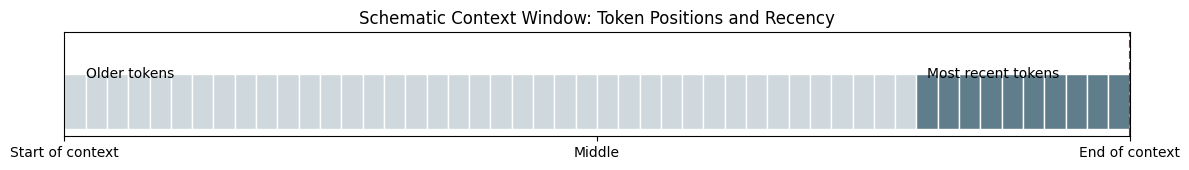

In [5]:
# --- new cell ---
import matplotlib.pyplot as plt
import numpy as np

# Parameters for the toy context window
total_window_size = 50        # total tokens in this schematic example
important_tail_size = 10      # last N tokens to highlight as "most recent"
context_limit = total_window_size  # set limit equal to window size for clarity

# Create a sequence of positions: 1..N (oldest -> newest)
positions = np.arange(1, total_window_size + 1)

# Color scheme: older tokens are lighter, recent ones darker
colors = []
for pos in positions:
    if pos <= total_window_size - important_tail_size:
        colors.append("#cfd8dc")  # light grey-blue for older context
    else:
        colors.append("#607d8b")  # darker for recent tokens

# Plotting
fig, ax = plt.subplots(figsize=(12, 1.8))

for pos, colour in zip(positions, colors):
    ax.barh(
        y=0,
        width=1,
        left=pos - 1,
        color=colour,
        edgecolor="white"
    )

# Red vertical context limit boundary
ax.axvline(context_limit, color="red", linestyle="--", linewidth=1.5, label="Context limit")

# Text labels
ax.text(1, 0.3, "Older tokens", fontsize=10, va="bottom", ha="left")
ax.text(total_window_size - important_tail_size + 0.5, 0.3, "Most recent tokens",
        fontsize=10, va="bottom", ha="left")

# Formatting axes
ax.set_yticks([])
ax.set_xticks([0, total_window_size // 2, total_window_size])
ax.set_xticklabels(["Start of context", "Middle", "End of context"])
ax.set_ylim(-0.5, 1)
ax.set_xlim(0, total_window_size)

ax.set_title("Schematic Context Window: Token Positions and Recency", fontsize=12)

plt.tight_layout()
plt.show()

### What this visualisation shows

- Each bar represents a **token slot** in the model’s context window.
- The last part of the window (right side) is shaded darker to represent **recency bias**, where LLMs typically place greater attention.
- The **red dashed line** marks the context limit. Any new tokens beyond this point
  push older tokens out of scope.
- Adjusting the window size demonstrates how modern LLMs handle context lengths ranging
  from a few thousand tokens to hundreds of thousands.

This helps understand why prompt placement, token count, and context budgeting
matter for reliable model behaviour.


## 4. Seed-controlled Sampling and Reproducibility

This example shows how fixing the random seed makes stochastic generation reproducible.
With the same prompt, model, decoding parameters, and **seed**, we obtain identical
outputs across runs. Changing only the seed produces a different continuation.

This illustrates why random seeds are essential for controlled experiments, A/B tests,
and debugging model behaviour.

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
import torch

model_name = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)
model.eval()

if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

def generate_with_seed(prompt: str, seed: int, temperature: float = 0.9, top_p: float = 0.95):
    set_seed(seed)
    inputs = tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=60,
            do_sample=True,
            temperature=temperature,
            top_p=top_p,
            pad_token_id=tokenizer.pad_token_id,
        )
    return tokenizer.decode(output_ids[0], skip_special_tokens=True)

prompt = "Explain in two or three sentences why reproducibility matters in language model evaluation."

print("=== Seed 42 — Run 1 ===")
print(generate_with_seed(prompt, seed=42))

print("\n=== Seed 42 — Run 2 (same seed, same output) ===")
print(generate_with_seed(prompt, seed=42))

print("\n=== Seed 7 — Run 3 (different seed, different output) ===")
print(generate_with_seed(prompt, seed=7))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

=== Seed 42 — Run 1 ===
Explain in two or three sentences why reproducibility matters in language model evaluation. The first sentence asks, "What does the definition of what is 'definition' mean?" The second says, "The definition of 'definition' is an object of inquiry and will be made explicit in the formalism of a language model as a function of the level of abstraction we want to make."

=== Seed 42 — Run 2 (same seed, same output) ===
Explain in two or three sentences why reproducibility matters in language model evaluation. The first sentence asks, "What does the definition of what is 'definition' mean?" The second says, "The definition of 'definition' is an object of inquiry and will be made explicit in the formalism of a language model as a function of the level of abstraction we want to make."

=== Seed 7 — Run 3 (different seed, different output) ===
Explain in two or three sentences why reproducibility matters in language model evaluation.

"Language is the most important to

## 5. Prompt Reordering and Order Effects

This experiment demonstrates how LLMs can produce different outputs even
when the *logical content* of a prompt remains the same. We take two instructions:

- “Summarise the article below in exactly three bullet points.”
- “Focus on the key risks mentioned in the text.”

Both prompts contain these same sentences, but we place them in different orders.  
Because LLMs weigh more recent tokens more heavily, the instruction that appears *later* in
the prompt often receives greater influence during generation.

By comparing the summaries produced by each reordered prompt, you can directly observe how
subtle changes in prompt geometry—ordering, emphasis, and recency shape the model’s
behaviour, even when the underlying task is unchanged.

In [9]:
model_name = "gpt2"

hf_tokenizer = AutoTokenizer.from_pretrained(model_name)
hf_model = AutoModelForCausalLM.from_pretrained(model_name)
hf_model.eval()

if hf_tokenizer.pad_token_id is None:
    hf_tokenizer.pad_token_id = hf_tokenizer.eos_token_id

def generate_with_temp(prompt: str, temperature: float = 0.7, max_new_tokens: int = 80, seed: int = 42):
    set_seed(seed)
    inputs = hf_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        output_ids = hf_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=temperature,
            top_p=0.9,
            pad_token_id=hf_tokenizer.pad_token_id,
        )
    return hf_tokenizer.decode(output_ids[0], skip_special_tokens=True)

In [10]:
article = """
Artificial intelligence systems are increasingly integrated into critical decision-making pipelines.
They can assist with medical diagnosis, loan approvals, and hiring decisions, but they also raise
concerns about fairness, transparency, and accountability.
"""

prompt_format_last = f"""
You are a careful, structured summariser.

Summarise the article below in exactly three bullet points.
Focus on the key risks mentioned in the text.

Article:
{article}
"""

prompt_focus_last = f"""
You are a careful, structured summariser.

Focus on the key risks mentioned in the text.
Summarise the article below in exactly three bullet points.

Article:
{article}
"""

print("=== Instruction order: format sentence last ===")
print(generate_with_temp(prompt_format_last, temperature=0.7, seed=123))

print("\n=== Instruction order: risk-focus sentence last ===")
print(generate_with_temp(prompt_focus_last, temperature=0.7, seed=123))


=== Instruction order: format sentence last ===

You are a careful, structured summariser.

Summarise the article below in exactly three bullet points.
Focus on the key risks mentioned in the text.

Article:

Artificial intelligence systems are increasingly integrated into critical decision-making pipelines.
They can assist with medical diagnosis, loan approvals, and hiring decisions, but they also raise
concerns about fairness, transparency, and accountability.


The primary threat to these systems is the ability to predict the future.


The problem is that they don't know the future.


They do not know the past.


They do not know the future.

They don't know how to predict the future.

They don't know how to control their own behavior.

They don't know how to communicate

=== Instruction order: risk-focus sentence last ===

You are a careful, structured summariser.

Focus on the key risks mentioned in the text.
Summarise the article below in exactly three bullet points.

Article:

A